In [26]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ntaganiraktheos/telco-customers/WA_Fn-UseC_-Telco-Customer-Churn.csv


**Loading dataset**

In [28]:
df = pd.read_csv("/kaggle/input/datasets/ntaganiraktheos/telco-customers/WA_Fn-UseC_-Telco-Customer-Churn.csv")

**Displaying head and tail**

In [29]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [30]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


**Data processing**

*changing churn attribute from yes/no to 1/0*

In [31]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


*Data type of each attribute*

In [32]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object


*COnvert attributes to appropriate datatypes*

In [33]:
# Convert categorical columns to category datatype
categorical_columns = [
    "gender", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod"
]

for column in categorical_columns:
    df[column] = df[column].astype("category")

# Convert numerical columns to appropriate datatypes
df["SeniorCitizen"] = df["SeniorCitizen"].astype("int64")
df["tenure"] = df["tenure"].astype("int64")
df["MonthlyCharges"] = df["MonthlyCharges"].astype("float64")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].astype("int64")

# Display the new datatypes
print(df.dtypes)


customerID            object
gender              category
SeniorCitizen          int64
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
Churn                  int64
dtype: object


*Null values*

In [34]:
null_values = df.isnull().sum()
print(df.isnull().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Toatal charges has 11 missing values

*Remove records with null or missing values*

In [35]:
print("Rows before cleaning:", len(df))
df = df.dropna().copy()
print("Rows after cleaning:", len(df))
print("Remaining null values:", df.isnull().sum().sum())

Rows before cleaning: 7043
Rows after cleaning: 7032
Remaining null values: 0


**Data exploitation**
churn rate = [(no of churn customers in a group)*100]/total customers in that group

*Gender distribution against churn*

        Stayed  Churned
gender                 
Female    2544      939
Male      2619      930

Churn rate by gender (%):
gender
Female    26.96
Male      26.20
Name: Churn, dtype: float64


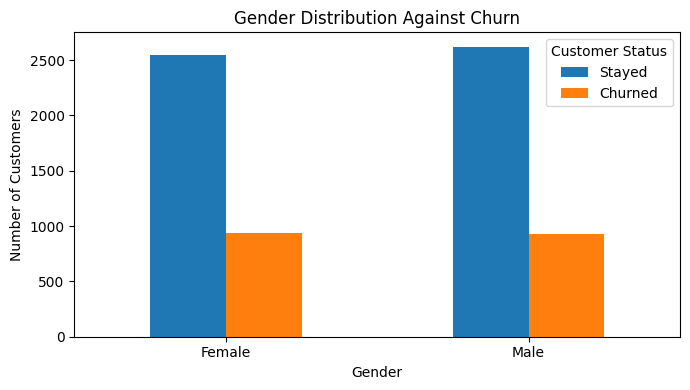

In [36]:
import matplotlib.pyplot as plt
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"]
)

gender_churn.columns = ["Stayed", "Churned"]

print(gender_churn)

gender_rate = (df.groupby(
    "gender", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by gender (%):")
print(gender_rate)

gender_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Gender Distribution Against Churn")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

*Senior against churn*

               Stayed  Churned
SeniorCitizen                 
0                4497     1393
1                 666      476

Churn rate by senior citizen status (%):
SeniorCitizen
0    23.65
1    41.68
Name: Churn, dtype: float64


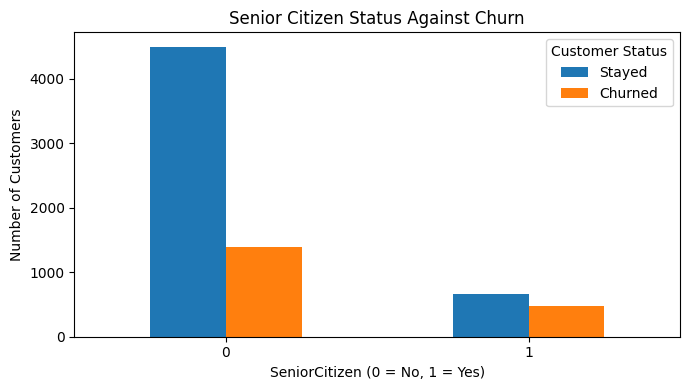

In [37]:
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"]
)

senior_churn.columns = ["Stayed", "Churned"]

print(senior_churn)

senior_rate = (df.groupby(
    "SeniorCitizen"
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by senior citizen status (%):")
print(senior_rate)

senior_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Senior Citizen Status Against Churn")
plt.xlabel("SeniorCitizen (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

*partner against churn*

         Stayed  Churned
Partner                 
No         2439     1200
Yes        2724      669

Churn rate by partner status (%):
Partner
No     32.98
Yes    19.72
Name: Churn, dtype: float64


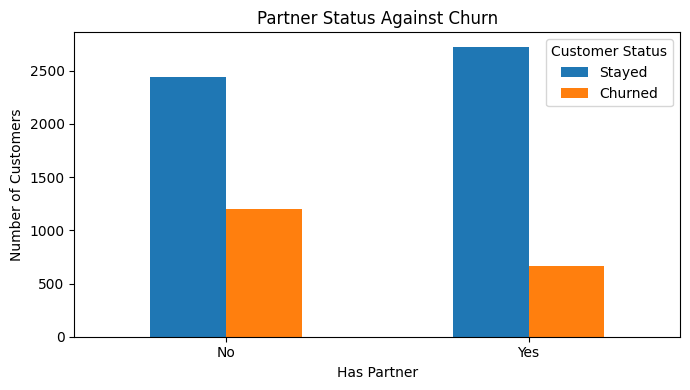

In [38]:
partner_churn = pd.crosstab(
    df["Partner"],
    df["Churn"]
)

partner_churn.columns = ["Stayed", "Churned"]

print(partner_churn)

partner_rate = (df.groupby(
    "Partner", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by partner status (%):")
print(partner_rate)

partner_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Partner Status Against Churn")
plt.xlabel("Has Partner")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

*dependents against churn*

            Stayed  Churned
Dependents                 
No            3390     1543
Yes           1773      326

Churn rate by dependents status (%):
Dependents
No     31.28
Yes    15.53
Name: Churn, dtype: float64


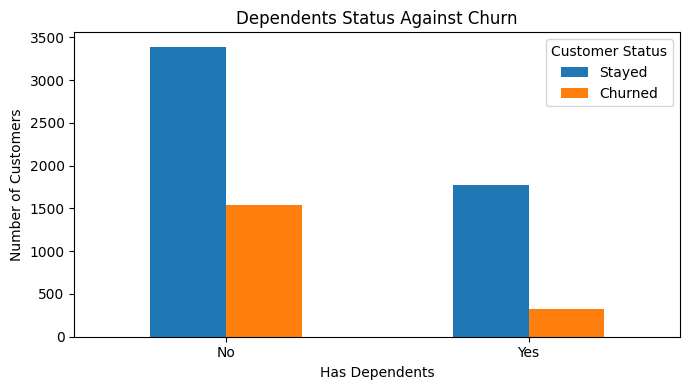

In [40]:
dependents_churn = pd.crosstab(
    df["Dependents"],
    df["Churn"]
)

dependents_churn.columns = ["Stayed", "Churned"]

print(dependents_churn)

dependents_rate = (df.groupby(
    "Dependents", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by dependents status (%):")
print(dependents_rate)

dependents_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Dependents Status Against Churn")
plt.xlabel("Has Dependents")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

**Phone service**

*phone service against churn*

              Stayed  Churned
PhoneService                 
No               510      170
Yes             4653     1699

Churn rate by phone service (%):
PhoneService
No     25.00
Yes    26.75
Name: Churn, dtype: float64


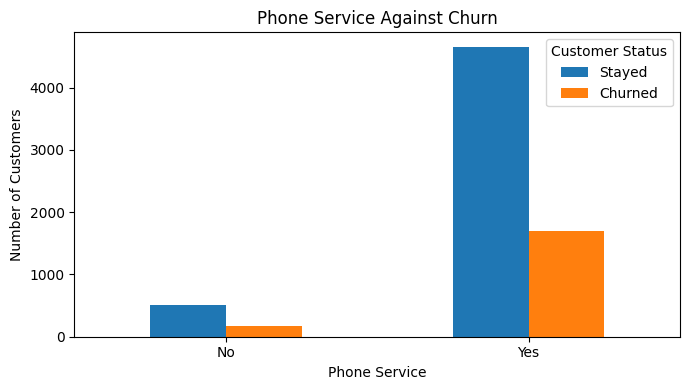

In [41]:
phone_churn = pd.crosstab(
    df["PhoneService"],
    df["Churn"]
)

phone_churn.columns = ["Stayed", "Churned"]

print(phone_churn)

phone_rate = (df.groupby(
    "PhoneService", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by phone service (%):")
print(phone_rate)

phone_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Phone Service Against Churn")
plt.xlabel("Phone Service")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

**Payment analysis**

*contract against churn*

                Stayed  Churned
Contract                       
Month-to-month    2220     1655
One year          1306      166
Two year          1637       48

Churn rate by contract type (%):
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn, dtype: float64


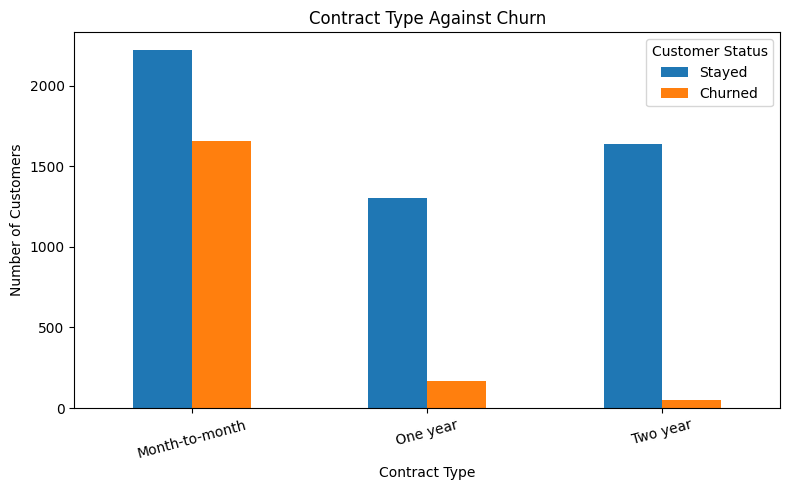

In [42]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_churn.columns = ["Stayed", "Churned"]

print(contract_churn)

contract_rate = (df.groupby(
    "Contract", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by contract type (%):")
print(contract_rate)

contract_churn.plot(kind="bar", figsize=(8, 5))
plt.title("Contract Type Against Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

*paperleass billing against churn*

                  Stayed  Churned
PaperlessBilling                 
No                  2395      469
Yes                 2768     1400

Churn rate by paperless billing (%):
PaperlessBilling
No     16.38
Yes    33.59
Name: Churn, dtype: float64


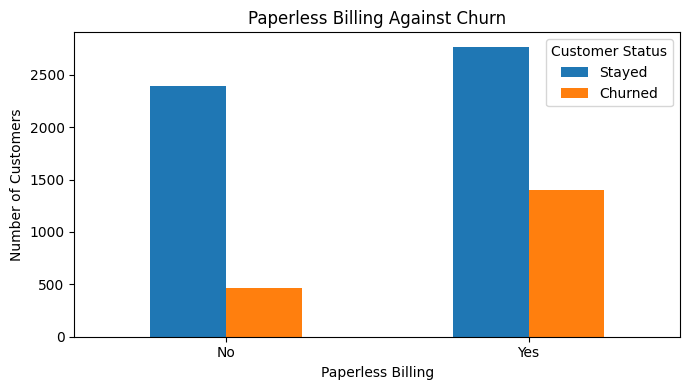

In [44]:
billing_churn = pd.crosstab(
    df["PaperlessBilling"],
    df["Churn"]
)

billing_churn.columns = ["Stayed", "Churned"]

print(billing_churn)

billing_rate = (df.groupby(
    "PaperlessBilling", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by paperless billing (%):")
print(billing_rate)

billing_churn.plot(kind="bar", figsize=(7, 4))
plt.title("Paperless Billing Against Churn")
plt.xlabel("Paperless Billing")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

*Paymentmethod agaisnt churn*

                           Stayed  Churned
PaymentMethod                             
Bank transfer (automatic)    1284      258
Credit card (automatic)      1289      232
Electronic check             1294     1071
Mailed check                 1296      308

Churn rate by payment method (%):
PaymentMethod
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Electronic check             45.29
Mailed check                 19.20
Name: Churn, dtype: float64


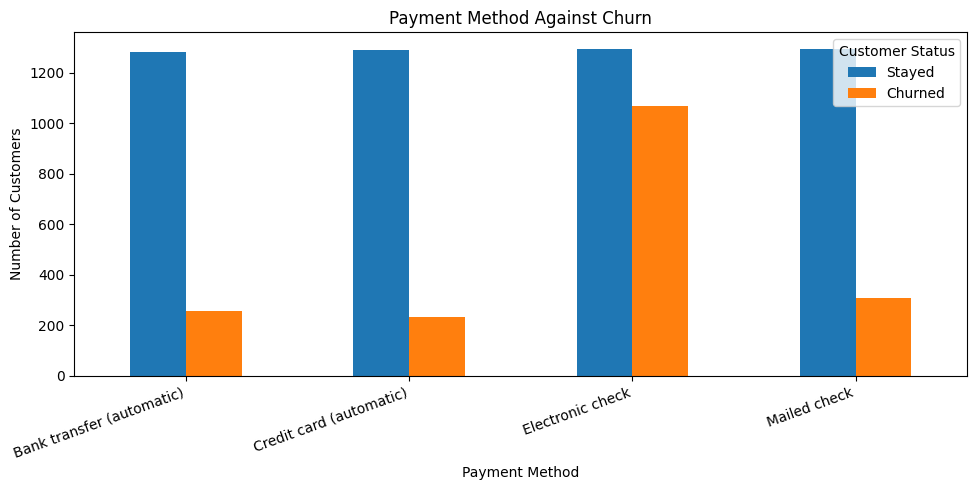

In [45]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_churn.columns = ["Stayed", "Churned"]

print(payment_churn)

payment_rate = (df.groupby(
    "PaymentMethod", observed=True
)["Churn"].mean() * 100).round(2)

print("\nChurn rate by payment method (%):")
print(payment_rate)

payment_churn.plot(kind="bar", figsize=(10, 5))
plt.title("Payment Method Against Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Customer Status")
plt.tight_layout()
plt.show()

**Overall conclusion**

The main findings are:
* Contract type: Month-to-month customers have a much higher churn rate than customers with one-year or two-year contracts.
* Payment method: Electronic check users have the highest churn rate among the payment groups.
* Senior citizen status: Senior citizens have a  higher churn rate than non-senior citizens.
* Family characteristics: Customers without partners or dependents have higher churn rates than their respective comparison groups.
* Gender and phone service: The differences in churn rates are relatively small for these attributes.
